# Homework 1 — complete code

Run the notebook from top to bottom. The first cell imports the course functions and prepares the data used by every later section.

In [27]:
# ============================================================
# SETUP AND DATA
# ============================================================

import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import chi2, f
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

COURSE_DIR = Path('/Users/poulcederholm/Desktop/ASVAR_ugesedler')
MASTER_DIR = COURSE_DIR / 'Master'
EXERCISE4_DIR = COURSE_DIR / 'Ugeseddel 4'
HW1_DIR = COURSE_DIR / 'HW1'

# Make the course master file importable.
if str(MASTER_DIR) not in sys.path:
    sys.path.insert(0, str(MASTER_DIR))

from s_master import (
    VARlsExog, lagmatrix, march, multnorm,
    comp, stabVAR, jcitestexog, johcontest,
)

# Locate the transformed data from Exercise 1.
DATA_CANDIDATES = [
    Path.cwd() / 'result.csv',
    Path.cwd() / 'results.csv',
    HW1_DIR / 'result.csv',
    COURSE_DIR / 'Ugeseddel 3' / 'result.csv',
    COURSE_DIR / 'Ugeseddel 1' / 'result.csv',
]
DATA_FILE = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(
        'Could not find result.csv. Looked in:\n  '
        + '\n  '.join(str(path) for path in DATA_CANDIDATES)
    )

data = pd.read_csv(DATA_FILE)

# Construct the exogenous intervention dummies from the dates.
quarters = pd.to_datetime(data['Dates']).dt.to_period('Q')
for name, quarter in [
    ('du93Q1', '1993Q1'),
    ('du92Q3', '1992Q3'),
    ('du95Q4', '1995Q4'),
]:
    data[name] = (quarters == pd.Period(quarter, freq='Q')).astype(int)

# Homework ordering: x_t = [rfor, lgdp, pi, dlrexc, rdom].
ENDOG = ['ForeignRate', 'GDP', 'Infl', 'ExchangeRate', 'IntRate']
DUMMIES = ['du93Q1', 'du92Q3', 'du95Q4']
y = data[ENDOG].to_numpy(float)
dummies_full = data[DUMMIES].to_numpy(float)

T_raw, K = y.shape
print('Using data file:', DATA_FILE)
print(f'T = {T_raw} observations, K = {K} variables')
print('Endogenous variables:', ENDOG)
print('Exogenous dummies:', DUMMIES)

Using data file: /Users/poulcederholm/Desktop/ASVAR_ugesedler/HW1/result.csv
T = 88 observations, K = 5 variables
Endogenous variables: ['ForeignRate', 'GDP', 'Infl', 'ExchangeRate', 'IntRate']
Exogenous dummies: ['du93Q1', 'du92Q3', 'du95Q4']


## Questions 2–3: lag-order selection

In [28]:
# Keep the deterministic regressors fixed across candidate lag orders.
# This gives every model the same effective sample for a given pmax.

def build_regressors(y, pmax, dum=None, trend=True):
    t, K = y.shape
    blocks = [np.ones((1, t - pmax))]  # constant
    if dum is not None:
        blocks.append(dum[pmax:t, :].T)
    if trend:
        blocks.append(np.arange(1, t - pmax + 1).reshape(1, -1))
    DET = np.vstack(blocks)
    LAGS = np.vstack([
        y[pmax - i:t - i, :].T for i in range(1, pmax + 1)
    ])
    Y = y[pmax:t, :].T
    return DET, LAGS, Y


def pfind_det(y, pmax, dum=None, trend=True):
    t, K = y.shape
    DET, LAGS, Y = build_regressors(y, pmax, dum, trend)
    T = t - pmax
    rows, logdet = [], []

    for m in range(pmax + 1):
        X = np.vstack([DET, LAGS[:m * K, :]]) if m else DET
        B = Y @ X.T @ np.linalg.inv(X @ X.T)
        residuals_m = Y - B @ X
        SIGMA_m = residuals_m @ residuals_m.T / T
        ld = np.log(np.linalg.det(SIGMA_m))
        logdet.append(ld)
        penalty_parameters = m * K**2 + K
        rows.append([
            m,
            ld + np.log(T) / T * penalty_parameters,
            ld + 2 * np.log(np.log(T)) / T * penalty_parameters,
            ld + 2 / T * penalty_parameters,
        ])

    table = pd.DataFrame(rows, columns=['Lag', 'SIC', 'HQ', 'AIC'])
    optimal = pd.DataFrame([{
        criterion: int(table.loc[table[criterion].idxmin(), 'Lag'])
        for criterion in ('SIC', 'HQ', 'AIC')
    }])
    return table, optimal, np.asarray(logdet), T


def top_down_sequence(y, pmax, dum=None, trend=True, significance=0.05):
    _, _, logdet, T = pfind_det(y, pmax, dum, trend)
    K = y.shape[1]
    rows = []
    for m in range(pmax, 0, -1):
        LR = T * (logdet[m - 1] - logdet[m])
        p_value = chi2.sf(LR, K**2)
        decision = 'reject' if p_value < significance else 'fail to reject'
        rows.append([m, LR, p_value, decision])
        if p_value < significance:
            break
    return pd.DataFrame(
        rows, columns=['H0: A_m = 0', 'LR', 'p-value', 'decision']
    )


for pmax in (4, 8, 12):
    _, optimal, _, _ = pfind_det(y, pmax, dummies_full, trend=True)
    print(f'pmax = {pmax}: optimal lag ->', optimal.to_dict('records')[0])

lag_table, optimal_lags, _, _ = pfind_det(
    y, pmax=4, dum=dummies_full, trend=True
)
print('\nInformation criteria, pmax = 4:')
display(lag_table.round(4))
display(optimal_lags)
print('Top-down sequence, pmax = 4:')
display(top_down_sequence(y, 4, dummies_full, trend=True).round(4))

pmax = 4: optimal lag -> {'SIC': 1, 'HQ': 1, 'AIC': 3}
pmax = 8: optimal lag -> {'SIC': 1, 'HQ': 1, 'AIC': 8}
pmax = 12: optimal lag -> {'SIC': 1, 'HQ': 12, 'AIC': 12}

Information criteria, pmax = 4:


,Lag,SIC,HQ,AIC
0,0,-3.7783,-3.8648,-3.9230
1,1,-10.5250,-11.0442,-11.3932
2,2,-9.7457,-10.6975,-11.3373
3,3,-9.0941,-10.4785,-11.4092
4,4,-8.0435,-9.8606,-11.0820


,SIC,HQ,AIC
0,1,1,3


Top-down sequence, pmax = 4:


,H0: A_m = 0,LR,p-value,decision
0,4,22.5223,0.6054,fail to reject
1,3,56.0370,0.0004,reject


## Questions 4–6: misspecification tests and stability

In [29]:
# Selected homework specification.
p = 3
con = 1
tr = 1
h = 4       # autocorrelation horizon for quarterly data
arch_lag = 2

# VARlsExog drops the first p observations, so align the dummies here.
exog_var = dummies_full[p:, :]


def VARLMtest(y, p, con, tr, exog, h):
    t, K = y.shape
    T = t - p
    (Beta, CovBeta, tratioBeta, residuals_u,
     X_u, SIGMA_u) = VARlsExog(y, p, con, tr, exog)

    # Auxiliary regression: retain the dummies and add residual lags.
    u_lags = lagmatrix(residuals_u, h)
    exog_aux = np.hstack([exog, u_lags])
    (Beta_e, CovBeta_e, tratioBeta_e, residuals_e,
     X_e, SIGMA_e) = VARlsExog(y, p, con, tr, exog_aux)

    # Lütkepohl/Breusch-Godfrey test.
    LML = T * (K - np.trace(np.linalg.inv(SIGMA_u) @ SIGMA_e))
    LML_pvalue = chi2.sf(LML, h * K**2)

    # Edgerton-Shukur small-sample correction.
    m = K * h
    q = 0.5 * K * m - 1
    s = np.sqrt((K**2 * m**2 - 4) / (K**2 + m**2 - 5))
    N = T - K * p - m - 0.5 * (K - m + 1)
    FLMh = (
        (np.linalg.det(SIGMA_u) / np.linalg.det(SIGMA_e))**(1 / s) - 1
    ) * ((N * s - q) / (K * m))
    FLMh_pvalue = f.sf(FLMh, K * m, N * s - q)

    results = [
        [LML, FLMh],
        [LML_pvalue, FLMh_pvalue],
        [h, h],
    ]
    lm_table = pd.DataFrame({
        'Measure': ['Test statistic', 'p-value', 'Lag order'],
        'Breusch_Godfrey': [row[0] for row in results],
        'Edgerton_Shukur': [row[1] for row in results],
    })
    return results, lm_table, residuals_u


LM_results, lm_table, residuals = VARLMtest(
    y, p, con, tr, exog_var, h
)
print('Multivariate autocorrelation tests:')
display(lm_table.round(4))

# The multivariate ARCH test uses arch_lag=2, not the VAR lag p.
arch_test, march_table = march(residuals, arch_lag, K)
print('Multivariate ARCH test:')
display(march_table)

normality_results, multnorm_table = multnorm(residuals)
print('Multivariate normality tests:')
display(multnorm_table)

# Built-in univariate checks from Exercise 3.
# Ljung-Box checks each residual series for autocorrelation at lag h.
# het_arch checks each residual series for ARCH effects at arch_lag.
names = ['rfor', 'lgdp', 'pi', 'dlrexc', 'rdom']
rows = []
for i in range(K):
    lb = acorr_ljungbox(
        residuals[:, i], lags=[h], return_df=True
    )
    lb_stat = lb['lb_stat'].values[0]
    lb_pvalue = lb['lb_pvalue'].values[0]

    arch_stat, arch_pvalue, arch_fstat, arch_fpvalue = het_arch(
        residuals[:, i], nlags=arch_lag
    )

    rows.append([
        lb_stat, lb_pvalue,
        arch_stat, arch_pvalue, arch_fstat, arch_fpvalue
    ])

univariate_table = pd.DataFrame(
    rows,
    index=names,
    columns=[
        'Ljung-Box(4) statistic', 'Ljung-Box(4) p-value',
        'ARCH(2) LM statistic', 'ARCH(2) LM p-value',
        'ARCH(2) F statistic', 'ARCH(2) F p-value'
    ]
)

print('Built-in univariate autocorrelation and ARCH checks:')
display(univariate_table.round(4))

# Stability of the selected VAR(3).
Beta, CovBeta, tratioBeta, residuals, X, SIGMA_u = VARlsExog(
    y, p, con, tr, exog_var
)
A = comp(Beta, p)
eigenvalue_moduli = stabVAR(A)
print(f'Largest eigenvalue modulus: {eigenvalue_moduli[0]:.4f}')
if eigenvalue_moduli[0] < 1:
    print('The VAR is stable.')
else:
    print('The VAR is not stable.')

Multivariate autocorrelation tests:


,Measure,Breusch_Godfrey,Edgerton_Shukur
0,Test statistic,131.9184,1.1314
1,p-value,0.0179,0.2252
2,Lag order,4.0000,4.0000


Multivariate ARCH test:


,Test,Doornik_Hendry
0,Test statistic,570.673166
1,P-value,0.000095
2,Degrees of freedom,450.000000


Multivariate normality tests:


,Test,Doornik_Hansen,Lutkepohl
0,Joint test statistic:,93.594,94.903
1,P-value,0.000,0.000
2,Degrees of freedom,10.000,10.000
3,Skewness only,11.989,9.055
4,P-value,0.035,0.107
5,Kurtosis only,81.606,85.848
6,P-value,0.000,0.000


Built-in univariate autocorrelation and ARCH checks:


,Ljung-Box(4) statistic,Ljung-Box(4) p-value,ARCH(2) LM statistic,ARCH(2) LM p-value,ARCH(2) F statistic,ARCH(2) F p-value
rfor,0.9213,0.9215,3.3467,0.1876,1.6806,0.1928
lgdp,0.4176,0.9810,4.7032,0.0952,2.4027,0.0970
pi,3.8135,0.4318,2.0604,0.3569,1.0182,0.3659
dlrexc,3.9180,0.4172,2.0386,0.3609,1.0072,0.3698
rdom,4.8863,0.2992,6.5234,0.0383,3.4119,0.0378


Largest eigenvalue modulus: 0.9460
The VAR is stable.


## Question 7: Johansen cointegration test

In [30]:
# The levels model contains a linear trend, so use Case 4 (H*).
# A VAR(3) corresponds to a VECM with p - 1 = 2 difference lags.
p = 3
model = 4

# jcitestexog expects the full 88-row dummy matrix and aligns it internally.
exog_johansen = dummies_full

# The course function loads its critical-value files with relative paths.
# Temporarily run it from the Exercise 4 folder containing those files.
previous_directory = Path.cwd()
try:
    os.chdir(EXERCISE4_DIR)
    (
        lr1, cval5, cval10, pval, eigenvalues,
        beta, alpha, c0, c1, d0, d1
    ) = jcitestexog(y, p - 1, exog_johansen, model)
finally:
    os.chdir(previous_directory)

# First rank whose trace test is not rejected at 5%.
trace_statistics = np.asarray(lr1).reshape(-1)
critical_values_5 = np.asarray(cval5).reshape(-1)
reject_at_5 = trace_statistics > critical_values_5
cointegration_rank = (
    int(np.flatnonzero(~reject_at_5)[0]) if np.any(~reject_at_5) else K
)
rank_table = pd.DataFrame({
    'H0: rank(Pi) = r': np.arange(K),
    'Trace statistic': trace_statistics,
    '5% critical value': critical_values_5,
    'p-value': np.asarray(pval).reshape(-1),
    'Reject at 5%': reject_at_5,
})
display(rank_table.round(4))
print(f'Estimated cointegration rank: r = {cointegration_rank}')
print(f'Common stochastic trends: K - r = {K - cointegration_rank}')
print('Note: critical values are approximate with exogenous I(0) variables.')


***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H* ("cili") [constant and linear trend in coint vec, linear trend in levels]
Model includes exogenous I(0) variables
Note: Critical values may not be correct
  r     stat    cVal5%    cVal10%    p-value    EigVal
---  -------  --------  ---------  ---------  --------
  0  120.057    88.804    84.3767      0.001    0.4316
  1   72.041    63.877    60.0879     0.0091    0.2639
  2   45.994    42.915    39.7549     0.0239    0.2404
  3   22.623    25.872    23.3427     0.1208    0.2113
  4    2.443    12.517    10.6662     0.9351    0.0283


***************************
ML estimates of beta.T, the cointegration vector
--------  --------  ---------  ---------  ---------
0.161871   8.47829  -0.630752  -0.417885   0.671298
0.297626   12.3698  0.0950799   0.434966   0.516576
0.734604  -7.24974   0.305332  -0.365651  -0.511814
0.561558   18.0028  -0.341737   0.304825  -

,H0: rank(Pi) = r,Trace statistic,5% critical value,p-value,Reject at 5%
0,0,120.0571,88.8042,0.0010,True
1,1,72.0413,63.8766,0.0091,True
2,2,45.9943,42.9154,0.0239,True
3,3,22.6226,25.8723,0.1208,False
4,4,2.4431,12.5174,0.9351,False


Estimated cointegration rank: r = 3
Common stochastic trends: K - r = 2
Note: critical values are approximate with exogenous I(0) variables.


## Question 8: estimated cointegration vectors

Following Exercise 5, compare H1 (a constant in the cointegration relation) with H* (a constant and linear trend in the cointegration relation). The restriction functions used from this point do not allow the intervention dummies, so these models are estimated without exogenous variables.


***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H1 ("ci") [constant in coint vec and linear trend in levels]
  r    stat    cVal5%    cVal10%    p-value    EigVal
---  ------  --------  ---------  ---------  --------
  0  102.87    69.819    65.8194      0.001    0.3492
  1  66.362    47.856    44.4932      0.001    0.2955
  2  36.591    29.798     27.066     0.0075    0.2078
  3  16.795    15.495    13.4295     0.0318    0.1792
  4    0.01     3.842     2.7055     0.9185    0.0001


***************************
ML estimates of beta.T, the cointegration vector
---------  --------  ----------  ----------  ---------
0.0875995   12.5686   -0.658327   -0.155466   0.839725
-0.367722  -14.8276   -0.205124   -0.465314  -0.242706
-0.316583  -2.21064  -0.0701213    0.546374   0.143648
-0.905367  0.661959    0.255283  -0.0718181   0.457817
---------  --------  ----------  ----------  ---------
ML estimates of alpha, th


***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H* ("cili") [constant and linear trend in coint vec, linear trend in levels]
  r     stat    cVal5%    cVal10%    p-value    EigVal
---  -------  --------  ---------  ---------  --------
  0  110.059    88.804    84.3767      0.001    0.3503
  1   73.408    63.877    60.0879     0.0068    0.3073
  2   42.195    42.915    39.7549      0.059    0.2332
  3   19.625    25.872    23.3427     0.2653    0.1881
  4    1.912    12.517    10.6662     0.9737    0.0222


***************************
ML estimates of beta.T, the cointegration vector
---------  --------  --------  ---------  ---------
-0.038107  -14.2065  0.690512   0.151885  -0.812661
 0.431686   6.66397  0.222785   0.298011   0.330696
0.0298683  -13.9665    0.1332  -0.667027  0.0183191
-0.887956  -6.49713  0.199969    0.12542     0.4648
---------  --------  --------  ---------  ---------
ML estimates of alph

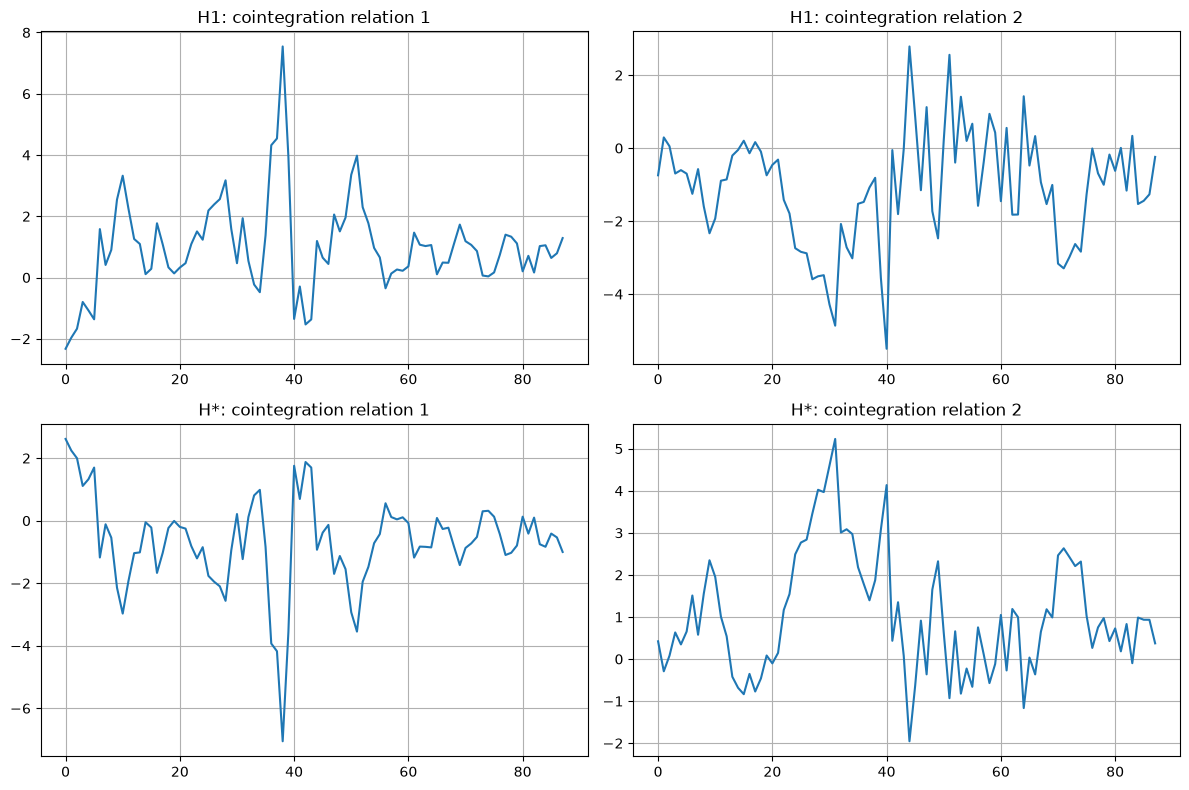

In [31]:
# H1: constant in the cointegration relation.
model = 3
exog = 0

previous_directory = Path.cwd()
try:
    os.chdir(COURSE_DIR / 'Ugeseddel 5')
    (lr_H1, cval5_H1, cval10_H1, pval_H1, l_H1, beta_H1, alpha_H1,
     c0_H1, c1_H1, d0_H1, d1_H1) = jcitestexog(y, p-1, exog, model)

    # H*: constant and linear trend in the cointegration relation.
    model = 4
    (lr_Hstar, cval5_Hstar, cval10_Hstar, pval_Hstar, l_Hstar,
     beta_Hstar, alpha_Hstar, c0_Hstar, c1_Hstar, d0_Hstar,
     d1_Hstar) = jcitestexog(y, p-1, exog, model)
finally:
    os.chdir(previous_directory)

r = cointegration_rank
betaorg_H1 = beta_H1[:, 0:r]
alphaorg_H1 = alpha_H1[:, 0:r]
betaorg_Hstar = beta_Hstar[:, 0:r]
alphaorg_Hstar = alpha_Hstar[:, 0:r]

print('First two beta vectors under H1:')
print(betaorg_H1[:, 0:2])
print('First two beta vectors under H*:')
print(betaorg_Hstar[:, 0:2])

# Construct and plot the first two estimated cointegration relations.
time = np.arange(1, T_raw + 1)
coint_H1_1 = y @ betaorg_H1[:, 0] + np.asarray(c0_H1).reshape(-1)[0]
coint_H1_2 = y @ betaorg_H1[:, 1] + np.asarray(c0_H1).reshape(-1)[1]
coint_Hstar_1 = (y @ betaorg_Hstar[:, 0]
                  + np.asarray(c0_Hstar).reshape(-1)[0]
                  + np.asarray(d0_Hstar).reshape(-1)[0] * time)
coint_Hstar_2 = (y @ betaorg_Hstar[:, 1]
                  + np.asarray(c0_Hstar).reshape(-1)[1]
                  + np.asarray(d0_Hstar).reshape(-1)[1] * time)


plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(coint_H1_1)
plt.title('H1: cointegration relation 1')
plt.grid(True)
plt.subplot(2, 2, 2)
plt.plot(coint_H1_2)
plt.title('H1: cointegration relation 2')
plt.grid(True)
plt.subplot(2, 2, 3)
plt.plot(coint_Hstar_1)
plt.title('H*: cointegration relation 1')
plt.grid(True)
plt.subplot(2, 2, 4)
plt.plot(coint_Hstar_2)
plt.title('H*: cointegration relation 2')
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretation of Question 8.** The unrestricted cointegration vectors are not unique: their signs, scales and linear combinations may change without changing the cointegration space. Therefore, the first two vectors cannot be given unique economic labels before restrictions are imposed. Under H*, a trend allows the long-run equilibrium to drift over time.

## Question 9: test the trend in the cointegration relation

As in Exercise 5, estimate H* and use `bcon` to test whether the final element of the augmented cointegration vector - the trend coefficient - is zero.

In [32]:
model = 'H*'
lags = float(p-1)
alpha_test = 0.05
r = float(cointegration_rank)

# H0: the trend coefficient in the cointegration relations is zero.
test = ['bcon']
cons = np.transpose(np.array([[0, 0, 0, 0, 0, 1]],
                             dtype=np.float64))
LRtest_trend, pval_trend, dof_trend, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(
    y, r, test, cons, model, lags, alpha_test
)

Testing restrictions on β in VEC model with cointegration rank =  3 

The constraint on β tested is
 [[0.0000 0.0000 0.0000 0.0000 0.0000 1.0000]] 


LR test of restriction with 3 degrees of freedom
Lr test statistic = 4.3596
with p-value =  0.2252 

Restricted estimates of alpha and beta
     α1       α2      α3       β1        β2       β3
-------  -------  ------  -------  --------  -------
-0.0588   0.0854  -0.011   0.0876   -0.3677   0.3166
-0.0027   0.0021  -0.001  12.5686  -14.8276   2.2106
 0.1817   0.0101  -0.139  -0.6583   -0.2051   0.0701
 0.6359   0.7443  0.7907  -0.1555   -0.4653  -0.5464
-0.3244  -0.1753   0.102   0.8397   -0.2427  -0.1436

 Restricted estimates of deterministic terms 

      c0
--------
-185.891
 219.076
 -32.288

        c1
----------
-0.0685634
0.00966528
 -0.160368
-0.0152739
  -0.10741

  d0
----
   0
   0
   0

  d1
----
 nan


**Interpretation of Question 9.** The p-value is 0.2252. At the 5% level, we do not reject that the trend coefficient is zero. We therefore continue with model H1, which has a constant but no trend in the cointegration relation.

## Question 10: stationarity, exclusion and weak exogeneity

The tests follow Exercise 5 exactly: `bvec` tests whether a unit vector belongs to the cointegration space (stationarity), `bcon` tests whether a variable can be excluded from all cointegration relations, and `acon` tests whether its adjustment coefficients are zero (weak exogeneity).

In [33]:
model = 'H1'
lags = float(p-1)
alpha_test = 0.05
r = float(cointegration_rank)

# Stationarity tests: bvec, one unit vector for each variable.
test = ['bvec']
cons = np.transpose(np.array([[1, 0, 0, 0, 0]], dtype=np.float64))
LRstat_rfor, pvalstat_rfor, dofstat_rfor, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 1, 0, 0, 0]], dtype=np.float64))
LRstat_lgdp, pvalstat_lgdp, dofstat_lgdp, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 1, 0, 0]], dtype=np.float64))
LRstat_pi, pvalstat_pi, dofstat_pi, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 1, 0]], dtype=np.float64))
LRstat_dlrexc, pvalstat_dlrexc, dofstat_dlrexc, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 0, 1]], dtype=np.float64))
LRstat_rdom, pvalstat_rdom, dofstat_rdom, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

# Exclusion tests: bcon, one unit vector for each variable.
test = ['bcon']
cons = np.transpose(np.array([[1, 0, 0, 0, 0]], dtype=np.float64))
LRexcl_rfor, pvalexcl_rfor, dofexcl_rfor, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 1, 0, 0, 0]], dtype=np.float64))
LRexcl_lgdp, pvalexcl_lgdp, dofexcl_lgdp, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 1, 0, 0]], dtype=np.float64))
LRexcl_pi, pvalexcl_pi, dofexcl_pi, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 1, 0]], dtype=np.float64))
LRexcl_dlrexc, pvalexcl_dlrexc, dofexcl_dlrexc, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 0, 1]], dtype=np.float64))
LRexcl_rdom, pvalexcl_rdom, dofexcl_rdom, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

# Weak-exogeneity tests: acon, one unit vector for each variable.
test = ['acon']
cons = np.transpose(np.array([[1, 0, 0, 0, 0]], dtype=np.float64))
LRweak_rfor, pvalweak_rfor, dofweak_rfor, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 1, 0, 0, 0]], dtype=np.float64))
LRweak_lgdp, pvalweak_lgdp, dofweak_lgdp, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 1, 0, 0]], dtype=np.float64))
LRweak_pi, pvalweak_pi, dofweak_pi, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 1, 0]], dtype=np.float64))
LRweak_dlrexc, pvalweak_dlrexc, dofweak_dlrexc, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

cons = np.transpose(np.array([[0, 0, 0, 0, 1]], dtype=np.float64))
LRweak_rdom, pvalweak_rdom, dofweak_rdom, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha_test)

# Collect all Question 10 results in one table

q10_table = pd.DataFrame([
    [
        'Stationarity', 'bvec', 'rfor', "[1, 0, 0, 0, 0]'",
        'rfor is stationary',
        float(LRstat_rfor), int(dofstat_rfor), float(pvalstat_rfor),
        'Reject H0' if pvalstat_rfor < alpha_test else 'Do not reject H0',
        'Not stationary' if pvalstat_rfor < alpha_test else 'Stationary'
    ],
    [
        'Stationarity', 'bvec', 'lgdp', "[0, 1, 0, 0, 0]'",
        'lgdp is stationary',
        float(LRstat_lgdp), int(dofstat_lgdp), float(pvalstat_lgdp),
        'Reject H0' if pvalstat_lgdp < alpha_test else 'Do not reject H0',
        'Not stationary' if pvalstat_lgdp < alpha_test else 'Stationary'
    ],
    [
        'Stationarity', 'bvec', 'pi', "[0, 0, 1, 0, 0]'",
        'pi is stationary',
        float(LRstat_pi), int(dofstat_pi), float(pvalstat_pi),
        'Reject H0' if pvalstat_pi < alpha_test else 'Do not reject H0',
        'Not stationary' if pvalstat_pi < alpha_test else 'Stationary'
    ],
    [
        'Stationarity', 'bvec', 'dlrexc', "[0, 0, 0, 1, 0]'",
        'dlrexc is stationary',
        float(LRstat_dlrexc), int(dofstat_dlrexc), float(pvalstat_dlrexc),
        'Reject H0' if pvalstat_dlrexc < alpha_test else 'Do not reject H0',
        'Not stationary' if pvalstat_dlrexc < alpha_test else 'Stationary'
    ],
    [
        'Stationarity', 'bvec', 'rdom', "[0, 0, 0, 0, 1]'",
        'rdom is stationary',
        float(LRstat_rdom), int(dofstat_rdom), float(pvalstat_rdom),
        'Reject H0' if pvalstat_rdom < alpha_test else 'Do not reject H0',
        'Not stationary' if pvalstat_rdom < alpha_test else 'Stationary'
    ],

    [
        'Exclusion', 'bcon', 'rfor', "[1, 0, 0, 0, 0]'",
        'rfor can be excluded',
        float(LRexcl_rfor), int(dofexcl_rfor), float(pvalexcl_rfor),
        'Reject H0' if pvalexcl_rfor < alpha_test else 'Do not reject H0',
        'Cannot be excluded' if pvalexcl_rfor < alpha_test
        else 'Can be excluded'
    ],
    [
        'Exclusion', 'bcon', 'lgdp', "[0, 1, 0, 0, 0]'",
        'lgdp can be excluded',
        float(LRexcl_lgdp), int(dofexcl_lgdp), float(pvalexcl_lgdp),
        'Reject H0' if pvalexcl_lgdp < alpha_test else 'Do not reject H0',
        'Cannot be excluded' if pvalexcl_lgdp < alpha_test
        else 'Can be excluded'
    ],
    [
        'Exclusion', 'bcon', 'pi', "[0, 0, 1, 0, 0]'",
        'pi can be excluded',
        float(LRexcl_pi), int(dofexcl_pi), float(pvalexcl_pi),
        'Reject H0' if pvalexcl_pi < alpha_test else 'Do not reject H0',
        'Cannot be excluded' if pvalexcl_pi < alpha_test
        else 'Can be excluded'
    ],
    [
        'Exclusion', 'bcon', 'dlrexc', "[0, 0, 0, 1, 0]'",
        'dlrexc can be excluded',
        float(LRexcl_dlrexc), int(dofexcl_dlrexc), float(pvalexcl_dlrexc),
        'Reject H0' if pvalexcl_dlrexc < alpha_test
        else 'Do not reject H0',
        'Cannot be excluded' if pvalexcl_dlrexc < alpha_test
        else 'Can be excluded'
    ],
    [
        'Exclusion', 'bcon', 'rdom', "[0, 0, 0, 0, 1]'",
        'rdom can be excluded',
        float(LRexcl_rdom), int(dofexcl_rdom), float(pvalexcl_rdom),
        'Reject H0' if pvalexcl_rdom < alpha_test else 'Do not reject H0',
        'Cannot be excluded' if pvalexcl_rdom < alpha_test
        else 'Can be excluded'
    ],

    [
        'Weak exogeneity', 'acon', 'rfor', "[1, 0, 0, 0, 0]'",
        'rfor is weakly exogenous',
        float(LRweak_rfor), int(dofweak_rfor), float(pvalweak_rfor),
        'Reject H0' if pvalweak_rfor < alpha_test else 'Do not reject H0',
        'Adjusts to disequilibrium' if pvalweak_rfor < alpha_test
        else 'Weakly exogenous'
    ],
    [
        'Weak exogeneity', 'acon', 'lgdp', "[0, 1, 0, 0, 0]'",
        'lgdp is weakly exogenous',
        float(LRweak_lgdp), int(dofweak_lgdp), float(pvalweak_lgdp),
        'Reject H0' if pvalweak_lgdp < alpha_test else 'Do not reject H0',
        'Adjusts to disequilibrium' if pvalweak_lgdp < alpha_test
        else 'Weakly exogenous'
    ],
    [
        'Weak exogeneity', 'acon', 'pi', "[0, 0, 1, 0, 0]'",
        'pi is weakly exogenous',
        float(LRweak_pi), int(dofweak_pi), float(pvalweak_pi),
        'Reject H0' if pvalweak_pi < alpha_test else 'Do not reject H0',
        'Adjusts to disequilibrium' if pvalweak_pi < alpha_test
        else 'Weakly exogenous'
    ],
    [
        'Weak exogeneity', 'acon', 'dlrexc', "[0, 0, 0, 1, 0]'",
        'dlrexc is weakly exogenous',
        float(LRweak_dlrexc), int(dofweak_dlrexc), float(pvalweak_dlrexc),
        'Reject H0' if pvalweak_dlrexc < alpha_test
        else 'Do not reject H0',
        'Adjusts to disequilibrium' if pvalweak_dlrexc < alpha_test
        else 'Weakly exogenous'
    ],
    [
        'Weak exogeneity', 'acon', 'rdom', "[0, 0, 0, 0, 1]'",
        'rdom is weakly exogenous',
        float(LRweak_rdom), int(dofweak_rdom), float(pvalweak_rdom),
        'Reject H0' if pvalweak_rdom < alpha_test else 'Do not reject H0',
        'Adjusts to disequilibrium' if pvalweak_rdom < alpha_test
        else 'Weakly exogenous'
    ]
], columns=[
    'Test',
    'Code',
    'Variable',
    'Restriction',
    'Null hypothesis',
    'LR statistic',
    'df',
    'p-value',
    'Decision (5%)',
    'Conclusion'
])

display(q10_table.round({
    'LR statistic': 4,
    'p-value': 4
}))


Testing restrictions on β in VEC model with cointegration rank =  3 

The constraint on β tested is
 [[1.0000 0.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 16.1994
with p-value =  0.0003 

Restricted estimates of alpha and beta
     α1       α2       α3    β1       β2        β3
-------  -------  -------  ----  -------  --------
-0.0337  -0.0579   0.0692     1        0         0
-0.0009  -0.0027   0.0016     0  12.4486  -14.5535
 0.0013   0.1822   -0.031     0    -0.66   -0.1917
-0.0684   0.6399   0.9546     0   -0.158   -0.6028
 0.0368  -0.3266  -0.1128     0   0.8383   -0.3029

 Restricted estimates of deterministic terms 

      c0
--------
 -3.8712
-183.963
 214.337

        c1
----------
-0.0966318
0.00823587
 -0.175975
-0.0107999
 -0.102279

  d0
----
 nan

  d1
----
 nan
Testing restrictions on β in VEC model with cointegration rank =  3 

The constraint on β tested is
 [[0.0000 1.0000 0.0000 0.0000 0.0000]] 


LR test of re

,Test,Code,Variable,Restriction,Null hypothesis,LR statistic,df,p-value,Decision (5%),Conclusion
0,Stationarity,bvec,rfor,"[1, 0, 0, 0, 0]'",rfor is stationary,16.1994,2,0.0003,Reject H0,Not stationary
1,Stationarity,bvec,lgdp,"[0, 1, 0, 0, 0]'",lgdp is stationary,19.3373,2,0.0001,Reject H0,Not stationary
2,Stationarity,bvec,pi,"[0, 0, 1, 0, 0]'",pi is stationary,9.8625,2,0.0072,Reject H0,Not stationary
3,Stationarity,bvec,dlrexc,"[0, 0, 0, 1, 0]'",dlrexc is stationary,0.1917,2,0.9086,Do not reject H0,Stationary
4,Stationarity,bvec,rdom,"[0, 0, 0, 0, 1]'",rdom is stationary,16.6717,2,0.0002,Reject H0,Not stationary
5,Exclusion,bcon,rfor,"[1, 0, 0, 0, 0]'",rfor can be excluded,2.1937,3,0.5332,Do not reject H0,Can be excluded
6,Exclusion,bcon,lgdp,"[0, 1, 0, 0, 0]'",lgdp can be excluded,15.6429,3,0.0013,Reject H0,Cannot be excluded
7,Exclusion,bcon,pi,"[0, 0, 1, 0, 0]'",pi can be excluded,16.9128,3,0.0007,Reject H0,Cannot be excluded
8,Exclusion,bcon,dlrexc,"[0, 0, 0, 1, 0]'",dlrexc can be excluded,7.8697,3,0.0488,Reject H0,Cannot be excluded
9,Exclusion,bcon,rdom,"[0, 0, 0, 0, 1]'",rdom can be excluded,15.1946,3,0.0017,Reject H0,Cannot be excluded


**Interpretation of Question 10 (5% level).** Stationarity is rejected for `rfor`, `lgdp`, `pi` and `rdom`, but not for `dlrexc`. `rfor` can be excluded from the cointegration space, while the other four variables cannot. `rfor` and `pi` are weakly exogenous; `lgdp`, `dlrexc` and `rdom` adjust to disequilibrium.

## Question 11: PPP and UIP restrictions

The VAR ordering is y_t = (i*_t, y_t, π_t, Δe_t, i_t)'. Because the dataset contains the **change** in the log real exchange rate rather than its level, the available PPP implication is stationarity of Δe_t, represented by β_PPP = (0,0,0,1,0)'. This is weaker than a direct test that the level of the real exchange rate is stationary. Bjørnland's UIP excess return is (i*_t - i_t) + 4Δs_(t+1). She converts the real exchange-rate change to a nominal change using domestic inflation (foreign prices are treated as exogenous), which gives the restriction β_UIP = (1,0,1,4,-1)' in the ordering used here.

Testing restrictions on β in VEC model with cointegration rank =  3 

The constraint on β tested is
 [[0.0000 0.0000 0.0000 1.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 0.1917
with p-value =  0.9086 

Restricted estimates of alpha and beta
     α1       α2       α3    β1        β2       β3
-------  -------  -------  ----  --------  -------
-0.0333   0.0641  -0.0799     0   -0.0983   0.3893
 0.0001   0.0027  -0.0022     0  -13.1841  14.4766
 0.0699  -0.1974  -0.0629     0    0.6528   0.2519
-0.8473  -0.5117  -0.5398     1         0        0
 0.0966    0.318      0.2     0   -0.8539   0.1891

 Restricted estimates of deterministic terms 

      c0
--------
-1.33545
 194.872
-212.773

        c1
----------
-0.0231075
 0.0119023
 -0.116023
-0.0200317
-0.0997021

  d0
----
 nan

  d1
----
 nan
Testing restrictions on β in VEC model with cointegration rank =  3 

The constraint on β tested is
 [[1.0000 0.0000 1.0000 4.0000 -1.0000]] 


LR test of re

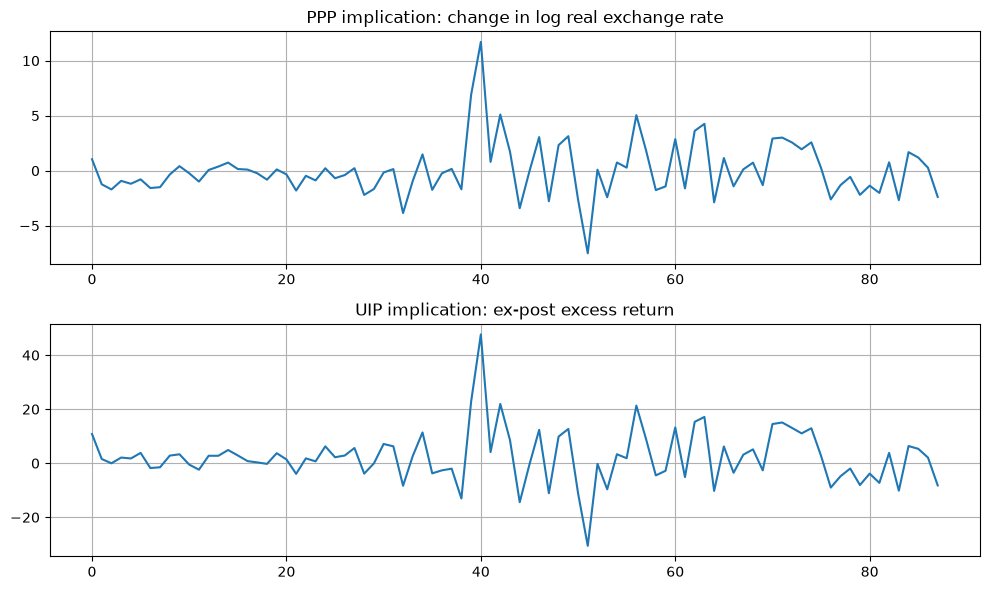

In [34]:
model = 'H1'
lags = float(p-1)
alpha_test = 0.05
r = float(cointegration_rank)
test = ['bvec']

# PPP restriction in the ordering (rfor, lgdp, pi, dlrexc, rdom).
cons_PPP = np.transpose(np.array([[0, 0, 0, 1, 0]],
                                 dtype=np.float64))
LRtest_PPP, pval_PPP, dof_PPP, Arest_PPP, Brest_PPP, c0r_PPP, c1r_PPP, d0r_PPP, d1r_PPP = johcontest(
    y, r, test, cons_PPP, model, lags, alpha_test
)

# UIP restriction in the ordering (rfor, lgdp, pi, dlrexc, rdom).
cons_UIP = np.transpose(np.array([[1, 0, 1, 4, -1]],
                                 dtype=np.float64))
LRtest_UIP, pval_UIP, dof_UIP, Arest_UIP, Brest_UIP, c0r_UIP, c1r_UIP, d0r_UIP, d1r_UIP = johcontest(
    y, r, test, cons_UIP, model, lags, alpha_test
)

# Plot the two theoretical cointegration relations as in Exercise 5.
coint_PPP = y @ cons_PPP
coint_UIP = y @ cons_UIP
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(coint_PPP)
plt.title('PPP implication: change in log real exchange rate')
plt.grid(True)
plt.subplot(2, 1, 2)
plt.plot(coint_UIP)
plt.title('UIP implication: ex-post excess return')
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretation of Question 11.** The PPP restriction has p-value 0.9086 and the UIP restriction has p-value 0.6368. Thus, neither restriction is rejected at the 5% level. The PPP result should be interpreted carefully because the dataset contains the change in the real exchange rate, not its level; it is therefore a weaker implication than the usual level-based PPP test.